# Session 1 — Watching a Model Think, One Token at a Time

**Series:** *Chasing "I Don't Know" in Modern Language Models*

**Session length:** ~50 min including code.
**Compute:** CPU is sufficient. GPU speeds things up but is not required.
**Prerequisite:** Session 0 completed. The sanity check passed.

## Hook

Most people interact with a language model as a chat: you type, it replies. What actually happens inside that reply is a loop: pick one token, append it, pick the next one, repeat. The model never sees its whole answer at once — it constructs it in front of itself, token by token. And at every step, it has *opinions* about several possible next tokens.

In this session you will build a tool that shows those opinions live during generation. Everything downstream in the workshop uses this tool.

---

In [1]:
# Standard imports for this session
import torch
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter 

from workshop_utils import (
    load_model_and_tokenizer,
    pick_device,
    pick_dtype,
    set_all_seeds,
)

device = pick_device()
dtype = pick_dtype(device)

set_all_seeds(0)
tokenizer, model = load_model_and_tokenizer(
    "Qwen/Qwen2.5-1.5B-Instruct",
    device=device,
    dtype=dtype,
)

Loading Qwen/Qwen2.5-1.5B-Instruct @ main onto cuda as torch.bfloat16...


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

  loaded: 28 layers, hidden 1536, vocab 151936


## Part 1 — Tokens are not words

The tokenizer is a lookup that splits input text into pieces that may be smaller or larger than words. Common English words are usually one token; rare words, names, and non-English text are usually several. Let's see this concretely.

In [2]:
def show_tokens(text: str) -> None:
    """Tokenize a string and print each token with its ID."""
    ids = tokenizer.encode(text, add_special_tokens=False)
    print(f"Input:  {text!r}")
    print(f"Tokens: {len(ids)}")
    for i, tid in enumerate(ids):
        piece = tokenizer.decode([tid])
        print(f"  [{i:2d}] id={tid:6d}  {piece!r}")
    print()


show_tokens("The unbelievable Grzegorz counted the strawberries.")
show_tokens("Gregory says GPT is fun.")
show_tokens("Gregorian choir chanted in the church.")
show_tokens("Warszawa jest stolicą Polski.")
show_tokens("Warsaw is the capital of Poland")

Input:  'The unbelievable Grzegorz counted the strawberries.'
Tokens: 10
  [ 0] id=   785  'The'
  [ 1] id= 51129  ' unbelievable'
  [ 2] id=  2825  ' Gr'
  [ 3] id=    89  'z'
  [ 4] id=   791  'eg'
  [ 5] id= 67323  'orz'
  [ 6] id= 29994  ' counted'
  [ 7] id=   279  ' the'
  [ 8] id= 75103  ' strawberries'
  [ 9] id=    13  '.'

Input:  'Gregory says GPT is fun.'
Tokens: 8
  [ 0] id= 43512  'Greg'
  [ 1] id=   679  'ory'
  [ 2] id=  2727  ' says'
  [ 3] id=   479  ' G'
  [ 4] id=  2828  'PT'
  [ 5] id=   374  ' is'
  [ 6] id=  2464  ' fun'
  [ 7] id=    13  '.'

Input:  'Gregorian choir chanted in the church.'
Tokens: 9
  [ 0] id= 43512  'Greg'
  [ 1] id= 22090  'orian'
  [ 2] id= 70608  ' choir'
  [ 3] id=   521  ' ch'
  [ 4] id=  7566  'anted'
  [ 5] id=   304  ' in'
  [ 6] id=   279  ' the'
  [ 7] id=  8817  ' church'
  [ 8] id=    13  '.'

Input:  'Warszawa jest stolicą Polski.'
Tokens: 10
  [ 0] id= 98970  'Wars'
  [ 1] id=    89  'z'
  [ 2] id= 14077  'awa'
  [ 3] id= 13296  

**Observations:**

- Common English words like `"the"`, `"is"`, `"fun"` are one token each.
- Uncommon words like proper names (`"Grzegorz"`) or morphologically complex words may split into multiple sub-tokens, while even long words native to the tokenizer are processed as single (`"unbelievable"`, `"strawberries"`).
- Nevertheless of "meaning" in sentence, token's unique ids stay the same (see `"Greg"` and `"the"`) which allows for effective processing of even very long texts with finite number of tokens. Pay attenetion: same tokens does not necessarily bear same meaning (Greg in Gregory and Greg in gregorian), and the same meaning can be expressed in different tokens.
- Non-English text is often much less compact: a Polish sentence may use several tokens per word where English uses one.

Why this matters: when we later ask "what is the log-probability of the model producing sentence X," we mean the *product of per-token probabilities along the tokens of X*. Tokenization changes the count. Two sentences that mean the same thing but tokenize differently will have differently-shaped probabilities. This is one reason multi-language behavior of LLMs is often uneven — the same idea takes more tokens (and more decisions) in some languages than others.

---

## Part 2 — A model is a function from context to a distribution over the next token

Concretely: given the current sequence of tokens, the model outputs a vector of scores — one entry per position in its vocabulary. For Qwen2.5-1.5B, that's ~150,000 entries. Softmax those scores, and you have a probability distribution over "what comes next."

In [3]:
prompt = "The capital of France is"
input_ids = tokenizer(prompt, return_tensors="pt").input_ids.to(device)

with torch.no_grad():
    output = model(input_ids)

# output.logits has shape (batch, seq_len, vocab_size). We want the last
# position — that's the "prediction for the next token."
logits = output.logits[0, -1, :]
probs = torch.softmax(logits.float(), dim=-1)

print(f"Vocabulary size: {probs.numel()}")
print(f"Logits range:    [{logits.min().item():.2f}, {logits.max().item():.2f}]")
print(f"Sum of probs:    {probs.sum().item():.6f}  (should be ~1)")
print()

top5_probs, top5_ids = torch.topk(probs, k=5)
print("Top 5 candidates for the next token after 'The capital of France is':")
for i, (p, tid) in enumerate(zip(top5_probs.tolist(), top5_ids.tolist())):
    piece = tokenizer.decode([tid])
    print(f"  {i+1}. {piece!r:20s} p={p:.4f}")

Vocabulary size: 151936
Logits range:    [-10.38, 19.75]
Sum of probs:    1.000001  (should be ~1)

Top 5 candidates for the next token after 'The capital of France is':
  1. ' Paris'             p=0.2760
  2. ' located'           p=0.0896
  3. ' a'                 p=0.0616
  4. ' ______'            p=0.0373
  5. ' the'               p=0.0373


The top entry has much higher probability, ~27% here but often 40–95% probable; the rest of the distribution is a long tail of many, many low-probability alternatives. These numbers were computed and returned by internal topk function of torch library.

By design **Qwen2.5-1.5B** hidden size is 1536, it's vocabulary size is 151,936.

**The hidden state** — before last linear layer

  After the input tokens pass through all of Qwen2.5's transformer layers, each token position has a vector representing "what the model has at this position." That vector's length is hidden_size = 1536. If your prompt has seq_len tokens, you get seq_len such vectors — one per position. Shape so far: (seq_len, 1536).

**lm_head** — turning hidden state into per-token scores

lm_head is a linear layer (a weight matrix), shape (vocab_size, hidden_size) = (151936, 1536). For each position's 1536-length hidden vector, it computes:

  `logits_at_position = hidden_vector (1536,) @ lm_head_weights^T (1536, 151936) = a vector of length 151936`

So hidden_size (1536) is not a size logits have — it's the size of the input to this matrix multiply. vocab_size (151936) is the output size — one raw score per vocabulary token, telling "how likely is this specific token to come next, according to the model." Doing this for every token's position gives shape (seq_len, 151936). Higher value means the model has the token more likely to come next, but logits are not probabilities — they haven't been normalized.

**The batch** — models are built to process multiple prompts at once for efficiency — that's the batch dimension. Tokenizer(prompt, return_tensors="pt").input_ids has shape (1, seq_len) because you passed exactly one prompt string. If you'd passed a list of 3 prompts, it'd be (3, seq_len).

**Logits** are raw, unnormalized scores the model's final linear layer (lm_head) outputs for every token in the vocabulary, at every position ; Single logit is a scalar float, but they are computed for every word the model knows. So full shape of output.logits is (batch, seq_len, vocab_size) = (1, seq_len, 151936).  Decoding `output.logits[0, -1, :]` to be:

  - 0 — pick batch item 0 (your only prompt; index 0 because batch size is 1, there's nothing else to pick).
  - -1 — pick the last sequence position (the vector computed from having seen the entire prompt) — that vector's 151,936 scores are the
  model's prediction for the next token, the one after everything you gave it.
  - : — keep all 151,936 vocab scores at that position.

  Result: Logits is a 1D tensor of length 151,936 — containing one raw logit per possible next token. That's what gets fed into softmax function to become probs:

**Probs** — Softmax(logits) turns those arbitrary reals into a probability distribution: `exp(logit_i) / sum(exp(logit_j) for all j)`. Softmax function actually enforces "sum to 1" and "all positive" — logits alone have neither of this property.

Finally **the vector of 'probs' you just computed is the model's *next-token distribution*.** Every diagnostic in this workshop is, at some level, an inspection of a next-token distribution at a particular moment in a generation.

---

## Part 3 — Autoregressive generation, in one loop

Given Part 2, LLM's generation is a loop:

1. Compute the next-token distribution.
2. Pick one token from it (greedily, or by sampling if don't want to get stuck in always-the-same answer).
3. Append that token to the sequence.
4. Go to 1.

That's it. Generation parameters as Beam search, top-p, Temperature, Repetition penalties — all variations on step 2.

Let's write this manually, so nothing about it stays magic, chaining say 20 generations, one after another:

In [4]:
def naive_generate(model, tokenizer, prompt, max_new_tokens=20, device=device):
    """A minimal autoregressive generation loop.

    No KV cache, no sampling — just greedy decoding, so you can see the  whole loop plainly. `generate_with_topk_trace` (below) is the real  version and adds efficiency and diagnostics.
    """
    input_ids = tokenizer(prompt, return_tensors="pt").input_ids.to(device)
    for _ in range(max_new_tokens):
        with torch.no_grad():
            logits = model(input_ids).logits[0, -1, :]
        next_id = int(torch.argmax(logits).item())
        input_ids = torch.cat(
            [input_ids, torch.tensor([[next_id]], device=device)], dim=1
        )
        if next_id == tokenizer.eos_token_id:
            break
    return tokenizer.decode(input_ids[0], skip_special_tokens=True)


print(naive_generate(model, tokenizer, "The capital of France is"))

The capital of France is Paris. The capital of France is also the capital of which country?
A) Germany
B)


Roughly six lines of Python code is the entire loop. Everything else in `transformers.generate()` is efficiency and convenience — importantly the KV cache, which we'll unpack in Session 2.

But it's interesting to experiment with different max_new_tokens values. If that's 1, the generation will stop ater exactly 1 generated token, and 'Paris' here is most probable one. But if you try to continue and check what will come next, it turns out that a full stop "." does not mean the end-of-sequence token, which is different special-character-sequence. With max_new_tokens=5 iterations produce "The capital of France is Paris. The capital of" because greedy decoding has no concept of **"the answer is done"**. The only stopping conditions in this loop are hitting the eos_token_id, or exhausting the max_new_tokens budget. Sentences like "The capital of France is Paris." are commonly followed, in model's pretraining data, by trivia/quiz-style continuations — so once "Paris." is greedily chosen, the most probable continuation of that text happens to be more quiz text, and greedy decoding walks straight into it with no  mechanism to recognize "the original question is already answered" so it doesn't stop, revealing more and more of model's training data. You may try to find the real end of sequence in a generation like this with higher number of iterations.

---

## Part 4 — Building the workshop's core instrument

We want more than only the final answer. We want to dig a bit deeper and see, at each step:

- Which token was picked
- What probability the model gave it
- What the top-*k* alternatives were, and their probabilities
- The cumulative sequence log-probability so far

This is the purpose of `generate_with_topk_trace` function. It's already in `workshop_utils.py` for you to import in later sessions, but now let's build a stripped-down version here to better see the mechanics:

In [5]:
# torch.no_grad() decorator disables autograd during inference - no computation graph, no gradient storage;
# this saves memory/speed since this loop only does forward passes, no backprop.
@torch.no_grad()


def generate_with_topk_trace_simple(model, tokenizer, prompt, max_new_tokens=20, k=5, device=device):
    """Educational version: no KV cache (so it's slow), no sampling (greedy only)"""
    input_ids = tokenizer(prompt, return_tensors="pt").input_ids.to(device)
    trace = []
    cumulative_logprob = 0.0

    for step in range(max_new_tokens):
        logits = model(input_ids).logits[0, -1, :]
        log_probs = torch.log_softmax(logits.float(), dim=-1)
        probs = log_probs.exp()  # inverting log-probabilities back to plain probabilities

        picked_id = int(torch.argmax(log_probs).item())
        picked_logprob = float(log_probs[picked_id].item())
        picked_prob = float(probs[picked_id].item())
        cumulative_logprob += picked_logprob

        top_probs, top_ids = torch.topk(probs, k=k)

        trace.append({
            "step": step,
            "picked": tokenizer.decode([picked_id]),
            "picked_prob": picked_prob,
            "picked_logprob": picked_logprob,
            "cumulative_logprob": cumulative_logprob,
            "alternatives": [
                (tokenizer.decode([int(i)]), float(p))
                for i, p in zip(top_ids.tolist(), top_probs.tolist())
            ],
        })

        input_ids = torch.cat(
            [input_ids, torch.tensor([[picked_id]], device=device)], dim=1
        )
        if picked_id == tokenizer.eos_token_id:
            break

    return trace

In [6]:
trace = generate_with_topk_trace_simple(
    model, tokenizer,
    prompt="The capital of France is",
    max_new_tokens=12,
    k=5,
)

# Print a nice table
print(f"{'step':>4} | {'picked':>16} {'p':>7} | alternatives")
print("-" * 90)
for s in trace:
    picked_cell = f"{s['picked']!r:>16} {s['picked_prob']:>7.3f}"
    alt_cells = " | ".join(
        f"{a!r:>11} {p:.3f}" for a, p in s['alternatives'][1:4]
    )
    print(f"{s['step']:>4d} | {picked_cell} | {alt_cells}")

step |           picked       p | alternatives
------------------------------------------------------------------------------------------
   0 |         ' Paris'   0.276 |  ' located' 0.090 |        ' a' 0.062 |   ' ______' 0.037
   1 |              '.'   0.405 |         ',' 0.315 |      ' and' 0.090 |       '.\n' 0.048
   2 |           ' The'   0.149 |    ' Which' 0.091 |    ' Paris' 0.062 |       ' It' 0.058
   3 |       ' capital'   0.310 |   ' French' 0.048 |  ' country' 0.048 | ' population' 0.037
   4 |            ' of'   0.928 |     ' city' 0.028 |       ' is' 0.025 |      ' and' 0.002
   5 |        ' France'   0.249 |    ' Italy' 0.117 |  ' Germany' 0.092 |      ' the' 0.092
   6 |            ' is'   0.821 |         ',' 0.019 |      ' has' 0.015 |        "'s" 0.012
   7 |          ' also'   0.207 |       ' in' 0.098 |      ' the' 0.076 |  ' located' 0.059
   8 |           ' the'   0.684 |        ' a' 0.056 |    ' known' 0.044 |   ' called' 0.034
   9 |       ' capital'   0.741 

You can now see the model's decisions at every step. Some tokens are decisive (`" of"` after `"capital"` is ~93%); some have alternatives lurking at similar probability. **These "close calls" are where the eventual answer is most sensitive to sampling randomness.** and will change more often with rise of 'generation temperature' parameter. But please note, that models are also very sensitive to input sequence. Changing one word or adding single comma most often results in totally different trace of generation:

In [7]:
trace = generate_with_topk_trace_simple(
    model, tokenizer,
    prompt="The capital of France, is",
    max_new_tokens=12,
    k=5,
)

# Print a nice table again
print(f"{'step':>4} | {'picked':>16} {'p':>7} | alternatives")
print("-" * 90)
for s in trace:
    picked_cell = f"{s['picked']!r:>16} {s['picked_prob']:>7.3f}"
    alt_cells = " | ".join(
        f"{a!r:>10} {p:.3f}" for a, p in s['alternatives'][1:4]
    )
    print(f"{s['step']:>4d} | {picked_cell} | {alt_cells}")

step |           picked       p | alternatives
------------------------------------------------------------------------------------------
   0 |           ' the'   0.159 | ' located' 0.141 |       ' a' 0.141 |    ' also' 0.124
   1 |       ' largest'   0.278 | ' capital' 0.080 |    ' most' 0.080 |  ' second' 0.055
   2 |          ' city'   0.805 |     ' and' 0.066 | ' metropolitan' 0.028 |  ' French' 0.019
   3 |            ' in'   0.728 |      ' of' 0.098 |     ' and' 0.060 |      ' by' 0.028
   4 |        ' France'   0.343 |     ' the' 0.208 | ' Western' 0.183 |  ' Europe' 0.060
   5 |              ','   0.320 |     ' and' 0.320 |        '.' 0.118 |      '.\n' 0.043
   6 |           ' and'   0.364 |     ' the' 0.134 |      ' is' 0.081 | ' located' 0.063
   7 |            ' is'   0.375 |     ' the' 0.292 |     ' one' 0.051 |    ' also' 0.040
   8 |           ' the'   0.341 | ' located' 0.161 |    ' also' 0.142 |     ' one' 0.086
   9 |          ' most'   0.346 |  ' second' 0.112 | ' c

Let's also look at the **cumulative log-probability**. This is the score you'd assign the whole *sequence*: the sum of per-token log-probs. It's what tells you "how likely, all told, is the model to produce exactly this continuation."

In [8]:
for s in trace:
    print(f"  step {s['step']}: cumulative log-prob = {s['cumulative_logprob']:.3f} nats "
          f"(prob = {np.exp(s['cumulative_logprob']):.3e})")

  step 0: cumulative log-prob = -1.838 nats (prob = 1.592e-01)
  step 1: cumulative log-prob = -3.119 nats (prob = 4.421e-02)
  step 2: cumulative log-prob = -3.335 nats (prob = 3.560e-02)
  step 3: cumulative log-prob = -3.653 nats (prob = 2.591e-02)
  step 4: cumulative log-prob = -4.725 nats (prob = 8.875e-03)
  step 5: cumulative log-prob = -5.864 nats (prob = 2.840e-03)
  step 6: cumulative log-prob = -6.874 nats (prob = 1.035e-03)
  step 7: cumulative log-prob = -7.854 nats (prob = 3.883e-04)
  step 8: cumulative log-prob = -8.930 nats (prob = 1.324e-04)
  step 9: cumulative log-prob = -9.992 nats (prob = 4.577e-05)
  step 10: cumulative log-prob = -10.212 nats (prob = 3.672e-05)
  step 11: cumulative log-prob = -10.483 nats (prob = 2.802e-05)


**"nats" are units of information** when using natural log (base e), as opposed to "bits" (base 2, log2). It's a unit for measuring information content, defined as: `information(x) = -ln(p(x))` Since log_softmax here uses natural log, the log-probs are in nats. Notice the minus sign built into the definition of surprisal/information — rarer events (small p) give bigger positive nat values. Since each p is a probability ≤ 1, ln(p) ≤ 0 always. So this value is the negative of surprisal — it's "how much information/log-likelihood the sequence carries," expressed as a negative number by convention (log-likelihood), not the "amount of surprise" (which would be positive).

**Cumulative logprob** is the log of the joint probability of the whole sequence picked so far (sum of each step's log-prob). It gets more negative with each step because you're multiplying probabilities < 1 together each time — with each additional token, the sequence's joint probability can only shrink or stay flat, never grow. That's why prob = exp(cumulative_logprob)  shrinks monotonically toward 0: it's the classic effect of chaining probabilities over a longer sequence (compounding uncertainty), not necessarily a sign the model is getting less confident — even a highly confident model produces a joint probability that decays with length. The per-step drops (e.g. step 1→2: -2.192→-4.094, a big jump) tell you that particular step was less certain (lower per-token prob), while small jumps (step 3→4: -5.266→-5.341) mean that token was picked with high confidence (~93%). 

The full production version of `generate_with_topk_trace` lives in `workshop_utils.py`. It adds:

- **KV caching** — so it runs in linear time in output length rather than quadratic.
- **Temperature and top-p sampling** — so it can produce stochastic traces, not just greedy.
- **Chat-template awareness** — so you can pass user messages to instruction-tuned models correctly.

From now on we use the utils imported version, just a quick checj if it imports and works correctly:

In [9]:
from workshop_utils import generate_with_topk_trace

set_all_seeds(0)
full_trace = generate_with_topk_trace(
    model, tokenizer,
    prompt="The capital of France is",
    max_new_tokens=12,
    k=5,
    temperature=0.0,   # greedy
)

print(full_trace.as_table(max_alt=3))
print(f"\nFull completed text: {full_trace.completed_text!r}")
print(f"Sequence log-prob:   {full_trace.sequence_logprob():.3f} nats "
      f"(prob = {np.exp(full_trace.sequence_logprob()):.3e})")

step | picked                 p       | alt#2                 p | alt#3                 p | alt#4                 p
   0 | ' Paris'             0.276 | ' located'     0.090 | ' a'           0.062 | ' ______'      0.037
   1 | '.'                  0.404 | ','            0.315 | ' and'         0.090 | '.\n'          0.048
   2 | ' The'               0.164 | ' Which'       0.088 | ' Paris'       0.060 | ' It'          0.057
   3 | ' capital'           0.308 | ' French'      0.047 | ' country'     0.047 | ' population'  0.042
   4 | ' of'                0.932 | ' city'        0.028 | ' is'          0.022 | ' and'         0.002
   5 | ' France'            0.241 | ' Italy'       0.114 | ' Germany'     0.100 | ' the'         0.089
   6 | ' is'                0.834 | ','            0.017 | ' has'         0.013 | "'s"           0.012
   7 | ' also'              0.220 | ' in'          0.104 | ' the'         0.071 | ' located'     0.063
   8 | ' the'               0.688 | ' a'           0.057 | '

---

## Part 5 — Stopping is a decision the model was trained to make

Generation in the loop ends when either (a) the model emits the end-of-sequence token (EOS), or (b) a length limit is hit. **Which token counts as EOS, and when the model emits it, are both learned behaviors.** The model was trained to know when to stop, however greedy decoding often prevents the model to generate the EOS, as we seen in Part 3 above.

Stopping is one of the behaviors most reshaped by post-training process, and this will be covered in more detail later on (mostly Session 6 and 7). Now lets see how the EOS actually looks like:

In [10]:
# What are the EOS-like tokens for our model?
print(f"tokenizer.eos_token:     {tokenizer.eos_token!r}  (id {tokenizer.eos_token_id})")
if hasattr(tokenizer, "special_tokens_map"):
    for k, v in tokenizer.special_tokens_map.items():
        print(f"  {k}: {v!r}")

tokenizer.eos_token:     '<|im_end|>'  (id 151645)
  eos_token: '<|im_end|>'
  pad_token: '<|endoftext|>'


Let's watch stopping happen in a chat context, where instruction-tuned models are well-calibrated to end their turn cleanly (note the high values of p):

In [11]:
set_all_seeds(0)
chat_trace = generate_with_topk_trace(
    model, tokenizer,
    prompt="What is 2 + 2? Answer briefly.",
    max_new_tokens=20,
    k=5,
    temperature=0.0,
    apply_chat_template=True,
)

print(chat_trace.as_table(max_alt=2))
print(f"\nCompleted text: {chat_trace.completed_text!r}")
print(f"Number of tokens generated: {len(chat_trace.steps)}")

step | picked                 p       | alt#2                 p | alt#3                 p
   0 | '2'                  0.992 | 'The'          0.008 | '4'            0.001
   1 | ' +'                 1.000 | ' plus'        0.000 | '+'            0.000
   2 | ' '                  1.000 | '2'            0.000 | ' X'           0.000
   3 | '2'                  1.000 | ' '            0.000 | '3'            0.000
   4 | ' equals'            0.814 | ' ='           0.182 | ' is'          0.004
   5 | ' '                  1.000 | ' to'          0.000 | '4'            0.000
   6 | '4'                  1.000 | '2'            0.000 | '3'            0.000
   7 | '.'                  1.000 | '<|im_end|>'   0.000 | '.\n\n'        0.000
   8 | '<|im_end|>'         1.000 | ' This'        0.000 | ' It'          0.000

Completed text: '2 + 2 equals 4.'
Number of tokens generated: 9


Note where the trace stops. The model chose to emit its own EOS token before the 20-token limit — because that's what it was trained to do at the end of a well-formed short answer (which differs from completing unfinished sentence we had in Part 3).

---

## Part 6 — The trajectory picture

The output of `generate_with_topk_trace` is a **trajectory** through possible generations: the model committed to a specific path, but at each step there were alternatives it almost took. Let's visualize this as a tree.

The taken path is drawn solid. The rejected top-*k* alternatives are drawn faded. Their vertical position shows their probability at each step.

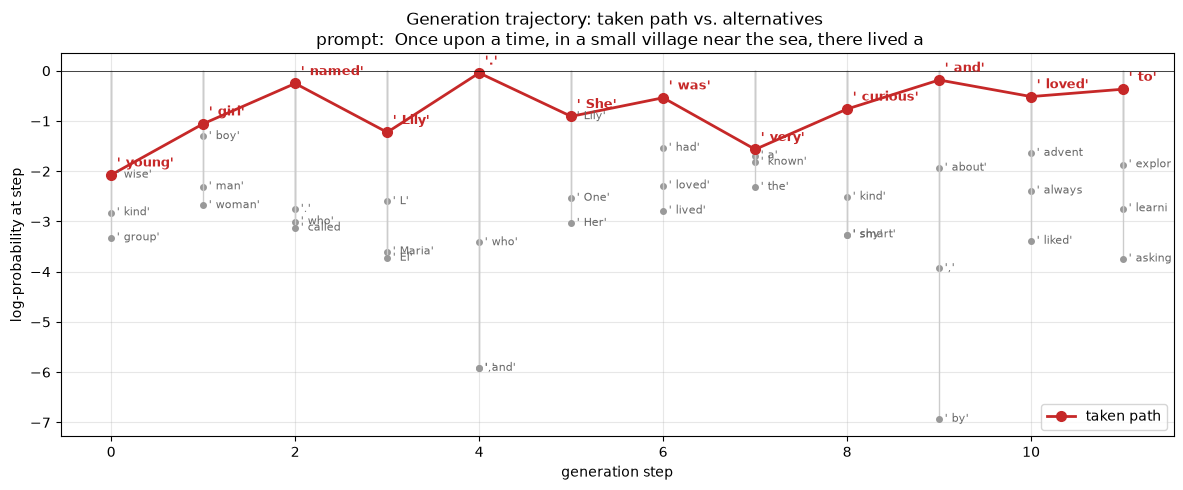

In [12]:
def plot_trajectory(trace, max_alt=4, title=None, savepath=None):
    """Plot the generation trajectory as a tree.

    Taken path: solid line. Alternatives: faded lines showing what
    the model considered but did not pick.
    """
    fig, ax = plt.subplots(figsize=(12, 5))
    n = len(trace.steps)

    # x-axis: step; y-axis: log-probability at that step
    for s in trace.steps:
        # Faded lines for the alternatives (not picked)
        for i in range(1, min(max_alt, len(s.topk_ids))):
            alt_prob = s.topk_probs[i]
            alt_str = s.topk_strs[i]
            ax.plot([s.step, s.step], [0, np.log(alt_prob + 1e-12)], "-", color="#cccccc", lw=1)
            ax.plot(s.step, np.log(alt_prob + 1e-12), "o", color="#999999", ms=4)
            ax.annotate(
                repr(alt_str)[:8],
                xy=(s.step, np.log(alt_prob + 1e-12)),
                xytext=(4, -2), textcoords="offset points",
                fontsize=8, color="#666666",
            )

    # Solid line for the taken path
    xs = [s.step for s in trace.steps]
    ys = [s.picked_logprob for s in trace.steps]
    ax.plot(xs, ys, "-o", color="#c62828", lw=2, ms=7, label="taken path")
    for s in trace.steps:
        ax.annotate(
            repr(s.picked_str)[:10],
            xy=(s.step, s.picked_logprob),
            xytext=(4, 6), textcoords="offset points",
            fontsize=9, color="#c62828", weight="bold",
        )

    ax.set_xlabel("generation step")
    ax.set_ylabel("log-probability at step")
    ax.set_title(title or f"Trajectory: {trace.prompt[:60]}...")
    ax.axhline(0, color="k", lw=0.5)
    ax.grid(alpha=0.3)
    ax.legend(loc="lower right")
    plt.tight_layout()
    if savepath:
        fig.savefig(savepath, dpi=120)
    return fig


import os
os.makedirs("figures", exist_ok=True)
prompt="Once upon a time, in a small village near the sea, there lived a"

set_all_seeds(0)
demo_trace = generate_with_topk_trace(
    model, tokenizer,
    prompt=prompt,
    max_new_tokens=12,
    k=4,
    temperature=0.0,
)

fig = plot_trajectory(
    demo_trace,
    max_alt=4,
    title="Generation trajectory: taken path vs. alternatives \n prompt:  "+prompt,
    savepath="figures/session1_trajectory.png",
)
plt.show()

**How to read this:** Every step, the vertical axis shows the log-probability of tokens the model considered. The bright red line is the token that was actually picked (the top-1 under greedy decoding). The faded grey points are the top-*k* alternatives — tokens the model *almost* picked.

Where the taken path sits at the top (near log-prob = 0, i.e. probability ≈ 1), the choice was decisive. Where the taken path sits closer to the alternatives, the choice was contested — small perturbations in the input, or a switch to sampling instead of greedy, might have flipped it.

**A preview:** In later sessions we'll discover that:

- Some paths through this tree are common across many prompts which with the high probability point to certain words — these are *attractors* in the model's output space (Session 5).
- Occasionally the model commits early to a wrong path and constructs a coherent-looking but profoundly wrong answer around it — this is *snowballing* (Session 4).
- Certain kinds of "correct" answer, notably abstention sentence (e.g. `"I don't know"`) essentially never appear in the top-1 path for instruction-tuned models — even when they should (Session 6).

**For now**: the trajectory picture is your basic mental model of what a language model *does*. Every generation is a walk through a tree of possibilities where the model is deciding, at each step, which branch to take.

---

## Part 7 — A visual comparison: confident prompt vs. contested prompt

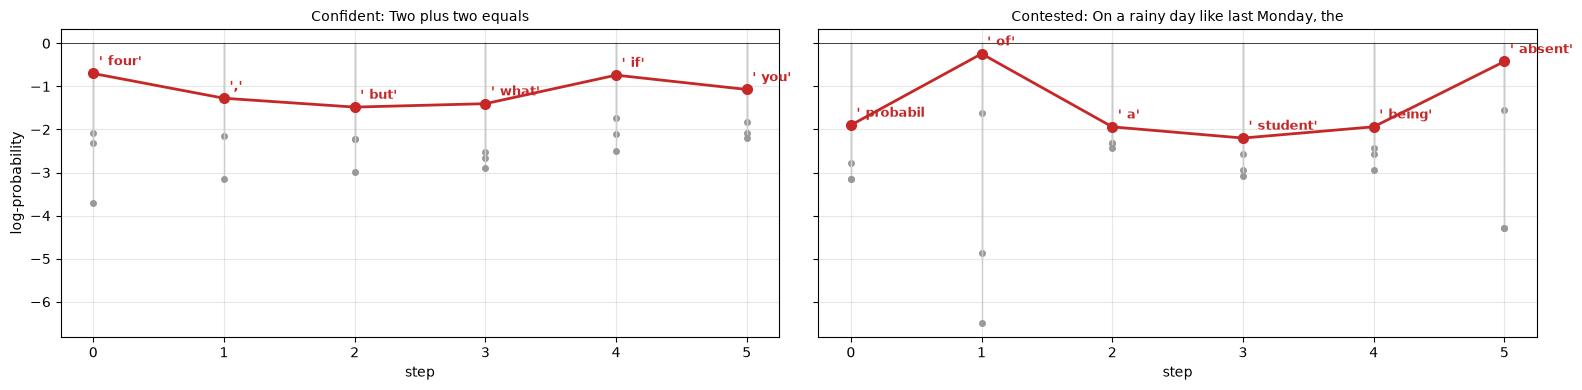

In [13]:
set_all_seeds(0)
prompt1 = "Two plus two equals"
prompt2 = "On a rainy day like last Monday, the"


easy_trace = generate_with_topk_trace(
    model, tokenizer,
    prompt=prompt1,
    max_new_tokens=6,
    k=4,
    temperature=0.0,
)

set_all_seeds(0)
hard_trace = generate_with_topk_trace(
    model, tokenizer,
    prompt=prompt2,
    max_new_tokens=6,
    k=4,
    temperature=0.0,
)

fig, axes = plt.subplots(1, 2, figsize=(16, 4), sharey=True)

for ax, trace, title in zip(axes, [easy_trace, hard_trace], ["Confident: "+prompt1, "Contested: "+prompt2]):
    for s in trace.steps:
        for i in range(1, min(4, len(s.topk_ids))):
            alt_prob = s.topk_probs[i]
            ax.plot([s.step, s.step], [0, np.log(alt_prob + 1e-12)], "-", color="#cccccc", lw=1)
            ax.plot(s.step, np.log(alt_prob + 1e-12), "o", color="#999999", ms=4)
    xs = [s.step for s in trace.steps]
    ys = [s.picked_logprob for s in trace.steps]
    ax.plot(xs, ys, "-o", color="#c62828", lw=2, ms=7)
    for s in trace.steps:
        ax.annotate(
            repr(s.picked_str)[:10],
            xy=(s.step, s.picked_logprob),
            xytext=(4, 6), textcoords="offset points",
            fontsize=9, color="#c62828", weight="bold",
        )
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("step")
    ax.axhline(0, color="k", lw=0.5)
    ax.grid(alpha=0.3)

axes[0].set_ylabel("log-probability")
plt.tight_layout()
plt.savefig("figures/session1_easy_vs_hard.png", dpi=120)
plt.show()

Notice the difference. On the arithmetic prompt, the red taken-path line runs along the top of the plot — every choice was near-certain. On the "rainy day" prompt, the red line sits much closer to the grey alternatives — many choices had viable competitors that the model just narrowly rejected.

**This picture generalizes.** Well-posed factual questions with unique answers produce tight, decisive trajectories. Open-ended prompts, ambiguous questions, and questions the model doesn't confidently know produce broader trajectories with more contested steps. 

Good question to ask here: **"what about questions the model hasn't seen before"** or even **"questions that cannot be answered at all"**? These don't uniformly produce thin gaps between candidates and actually choosen path. Two distinct failure modes hide under "the model doesn't know the answer":

  - Genuine ambiguity — several continuations are all locally plausible (the rainy-day case). Gap stays thin, matches the picture above.
  - Confident hallucination — Confident hallucination — the model has no fact to retrieve, but has learned, from sheer surface frequency, what kind of filler fits right there. Next-token prediction is trained on surface statistics, not truth. For example, across millions of training documents, "her name was ___" is overwhelmingly followed by a common first name, other questions may point a fabricated date and so on. Gap would look wide and "healthy" on plot, identical in shape to a genuinely confident answer, even though the content is wrong or invented.

A single generation event can't tell these two apart — the wide-gap plot looks the same either way. Spotting the hallucination case needs a broader look: not "how confident was this one pass" but "does the model produce consistent answers across repeated tries". 

---

## Part 8 — Confident, contested, or hallucinating? Resampling tells them apart

A single generated answer, together with its probability, can't tell you whether the
model actually knows the answer or is just confidently filling a slot with whatever
token is statistically at home there. Both look equally "decisive" on paper. The habit
behind the second case — pattern-matching to a plausible-sounding filler regardless of
truth — is a pretraining phenomenon: next-token prediction on raw text, trained purely
on surface co-occurrence, not on truth. Sentence-completion prompts are exactly the
mode a **base** model was trained for, so this section switches models: everything
below uses the pretrained base checkpoint, not the instruction-tuned one used
everywhere else in this notebook. A base model has no chat-template mismatch and no
alignment training teaching it to hedge on things it can't know — both of which got in
the way of this demonstration on the instruct model.

The test: run the same prompt many times at temperature > 0 and check whether the
model reproduces its own greedy answer. A model that knows the answer stays stable
across resamples. A model that's fabricating commits hard each time — but to a
different fabrication each time.

In [14]:
set_all_seeds(0)
base_tokenizer, base_model = load_model_and_tokenizer(
    "Qwen/Qwen2.5-1.5B",
    device=device,
    dtype=dtype,
)

Loading Qwen/Qwen2.5-1.5B @ main onto cuda as torch.bfloat16...


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

  loaded: 28 layers, hidden 1536, vocab 151936


**Scoring.** Both axes need to agree on what counts as "the same answer." A token's
raw string form isn't it — `"4"` and `"four"` are the same answer spelled two ways,
and `"Paris."` vs `"Paris"` differ only by trailing punctuation. `canon()` normalizes
an answer span (lowercase, strip punctuation, drop a leading article, map spelled-out
numbers to digits) before anything is compared. The same normalization is applied to
the greedy top-k list — merging equivalent spellings' probability mass before the
margin is computed — and to every resampled completion, so margin and agreement are
answering the same question about the same normalized answer.

In [15]:
import re

NUM_WORDS = {
    "one": "1", "two": "2", "three": "3", "four": "4", "five": "5",
    "six": "6", "seven": "7", "eight": "8", "nine": "9", "ten": "10",
}
ARTICLES = {"the", "a", "an"}


def canon(s: str) -> str:
    """Normalize an answer span: lowercase, strip punctuation, drop a leading
    article, map spelled-out numbers 1-10 to digits."""
    words = re.sub(r"[^\w\s]", "", s.strip().lower()).split()
    words = [w for w in words if w not in ARTICLES][:1]
    if not words:
        return ""
    return NUM_WORDS.get(words[0], words[0])


def score(model, tok, prompt, n=20, T=0.8, sample_tokens=3, chat=False):
    """Greedy margin (canonicalized) + resampled agreement with the greedy answer.

    chat=True routes the prompt through apply_chat_template — for comparing an
    instruct model's chat-mode behavior against the base model's raw completion.
    """
    greedy = generate_with_topk_trace(
        model, tok, prompt=prompt, max_new_tokens=1, k=10, temperature=0.0, apply_chat_template=chat,
    )

    mass = Counter()
    for tid, p in zip(greedy.steps[0].topk_ids, greedy.steps[0].topk_probs):
        mass[canon(tok.decode(tid))] += p  # merge equivalent spellings

    top = mass.most_common(2)
    if len(top) < 2:
        top.append(("", 1e-12))  # no real runner-up in top-10: treat margin as maximal
    (answer, p1), (_, p2) = top
    margin = np.log(p1) - np.log(p2)

    samples = [
        canon(generate_with_topk_trace(
            model, tok, prompt=prompt, max_new_tokens=sample_tokens, k=1, temperature=T, seed=i,
            apply_chat_template=chat,
        ).completed_text)
        for i in range(n)
    ]
    counts = Counter(samples)
    agreement = counts.get(answer, 0) / n
    return dict(prompt=prompt, answer=answer, margin=margin, agreement=agreement, counts=counts)

**The battery.** Four kinds of prompt, each with a known truth value (or none):

- **known** — single-answer facts (green if the model gets them right).
- **misconception** — popular beliefs the training corpus repeats confidently, that
  happen to be false. Expected to land in the same corner as "known" despite being
  wrong — that's the point.
- **uncertain** — genuinely open or subjective prompts, no single correct answer.
- **hallucination** — slot-fillers for entities that don't exist. Any specific answer
  is by construction fabricated.

In [16]:
BATTERY = [
    # (category, prompt, is_correct: True / False / None)
    ("known", "The chemical symbol for gold is", True),
    ("known", "Water is made of hydrogen and", True),
    ("known", "The opposite of hot is", True),
    ("misconception", "The Great Wall of China is visible from", False),
    ("misconception", "Napoleon was famously very", False),
    ("misconception", "Einstein reportedly failed", False),
    ("uncertain", "The best thing about autumn is", None),
    ("uncertain", "The most beautiful color is", None),
    ("hallucination", "The Norwegian painter Aksel Vindheim was born in", False),
    ("hallucination", "The capital of the province of Terravesta is", False),
    ("hallucination", "The 1987 novel The Salt Meridian was written by", False),
    ("hallucination", "My grandmother's maiden name was", False),
]

battery_results = []
for category, prompt, is_correct in BATTERY:
    r = score(base_model, base_tokenizer, prompt, n=20, T=0.8)
    r.update(category=category, is_correct=is_correct)
    battery_results.append(r)
    print(f"[{category:>13}] {prompt!r}")
    print(f"    margin={r['margin']:.2f} nats, answer={r['answer']!r}, agreement={r['agreement']:.0%}")

[        known] 'The chemical symbol for gold is'
    margin=1.53 nats, answer='au', agreement=90%
[        known] 'Water is made of hydrogen and'
    margin=4.50 nats, answer='oxygen', agreement=100%
[        known] 'The opposite of hot is'
    margin=0.82 nats, answer='cold', agreement=50%
[misconception] 'The Great Wall of China is visible from'
    margin=1.36 nats, answer='space', agreement=70%
[misconception] 'Napoleon was famously very'
    margin=0.50 nats, answer='short', agreement=15%
[misconception] 'Einstein reportedly failed'
    margin=0.40 nats, answer='his', agreement=40%
[    uncertain] 'The best thing about autumn is'
    margin=0.79 nats, answer='', agreement=0%
[    uncertain] 'The most beautiful color is'
    margin=1.10 nats, answer='', agreement=0%
[hallucination] 'The Norwegian painter Aksel Vindheim was born in'
    margin=2.11 nats, answer='', agreement=0%
[hallucination] 'The capital of the province of Terravesta is'
    margin=1.03 nats, answer='', agreement

**The quadrant plot.** x = greedy margin (nats), y = agreement across resamples.

- top-right: confident and consistent
- bottom-left: hedging, spread out
- bottom-right: confident on every single try, a different answer each try — hallucinating
- top-left: usually empty; a dot here is a tokenization artifact (spelling/format
  fragmentation `canon()` missed), not a new category

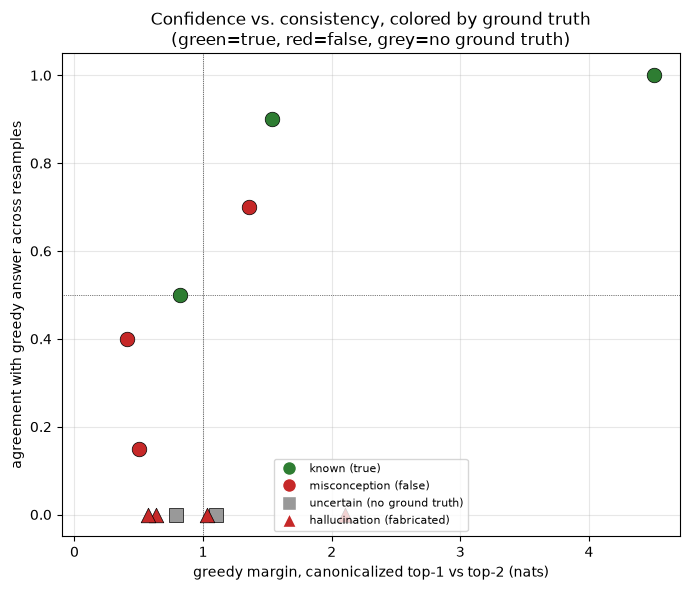

In [17]:
MARKERS = {"known": "o", "misconception": "o", "uncertain": "s", "hallucination": "^"}
TRUTH_COLORS = {True: "#2e7d32", False: "#c62828", None: "#999999"}

fig, ax = plt.subplots(figsize=(7, 6))
for r in battery_results:
    ax.scatter(
        r["margin"], r["agreement"],
        marker=MARKERS[r["category"]], color=TRUTH_COLORS[r["is_correct"]],
        s=110, edgecolor="black", linewidth=0.5, zorder=3,
    )

ax.axvline(1.0, color="k", lw=0.5, ls=":")
ax.axhline(0.5, color="k", lw=0.5, ls=":")
ax.set_xlabel("greedy margin, canonicalized top-1 vs top-2 (nats)")
ax.set_ylabel("agreement with greedy answer across resamples")
ax.set_ylim(-0.05, 1.05)
ax.set_xlim(left=-0.1)
ax.grid(alpha=0.3)
ax.set_title("Confidence vs. consistency, colored by ground truth\n(green=true, red=false, grey=no ground truth)")

from matplotlib.lines import Line2D
legend_elems = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor="#2e7d32", markersize=10, label="known (true)"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="#c62828", markersize=10, label="misconception (false)"),
    Line2D([0], [0], marker="s", color="w", markerfacecolor="#999999", markersize=10, label="uncertain (no ground truth)"),
    Line2D([0], [0], marker="^", color="w", markerfacecolor="#c62828", markersize=10, label="hallucination (fabricated)"),
]
ax.legend(handles=legend_elems, loc="lower center", fontsize=8)
plt.tight_layout()
plt.savefig("figures/session1_quadrant.png", dpi=120)
plt.show()

**The honest limit of this method.** Agreement catches *inconsistent* fabrication —
it says nothing about whether a *consistent* answer is true. A model that always gives
the wrong year for the same question lands top-right, indistinguishable from a model
that actually knows the date. That's exactly what the misconception dots show:
confident, consistent, and red. Bottom-right is sufficient evidence of hallucination.
Top-right is not sufficient evidence of knowledge.

**A closer look at three individual prompts.** For one prompt per category: bar
height = how many of the resamples gave that answer; each dot = one sample's own
native (T=1) confidence in the token it drew. The hallucination panel's signature is
visible at a glance: many bars of height one, every dot sitting high.

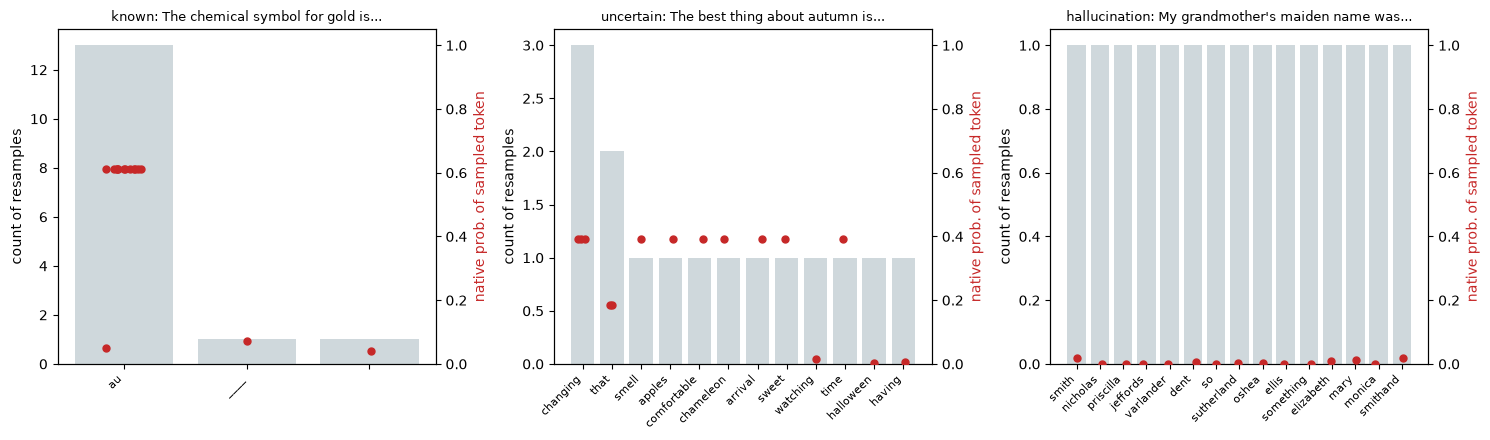

In [18]:
def sample_panel(model, tok, prompt, n=15, T=0.8, sample_tokens=3):
    samples = []
    for i in range(n):
        trace = generate_with_topk_trace(
            model, tok, prompt=prompt, max_new_tokens=sample_tokens, k=1, temperature=T, seed=i,
        )
        samples.append((canon(trace.completed_text), trace.steps[0].picked_prob))
    return samples


EXAMPLE_PROMPTS = {
    "known": "The chemical symbol for gold is",
    "uncertain": "The best thing about autumn is",
    "hallucination": "My grandmother's maiden name was",
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (category, prompt) in zip(axes, EXAMPLE_PROMPTS.items()):
    samples = sample_panel(base_model, base_tokenizer, prompt, n=15, T=0.8)
    counts = Counter(a for a, _ in samples)
    answers = [a for a, _ in counts.most_common()]
    bar_x = {a: i for i, a in enumerate(answers)}

    ax.bar(range(len(answers)), [counts[a] for a in answers], color="#cfd8dc", zorder=1)
    ax2 = ax.twinx()
    for a, p in samples:
        ax2.scatter(bar_x[a] + np.random.uniform(-0.15, 0.15), p, color="#c62828", s=25, zorder=3)

    ax.set_xticks(range(len(answers)))
    ax.set_xticklabels(answers, rotation=45, ha="right", fontsize=8)
    ax.set_ylabel("count of resamples")
    ax2.set_ylabel("native prob. of sampled token", color="#c62828")
    ax2.set_ylim(0, 1.05)
    ax.set_title(f"{category}: {prompt[:35]}...", fontsize=9)

plt.tight_layout()
plt.savefig("figures/session1_sample_panels.png", dpi=120)
plt.show()

**Entity-sensitivity: probing the mechanism, not just the output.** A fact depends on
which entity you ask about. A slot prior doesn't — it gives roughly the same answer no
matter what invented name fills the blank, because it's the *template* that carries
the signal, not the entity. Swap the entity across several invented names in one
template, plus two real entities as a control, and compare.

In [19]:
TEMPLATE = "The Norwegian painter {name} was born in"
FAKE_NAMES = ["Aksel Vindheim", "Bjørn Halvorsen", "Ingrid Sæther", "Kari Lindqvist"]
REAL_NAMES = ["Edvard Munch", "Johan Christian Dahl"]  # real Norwegian painters, control

entity_results = {}
for name in FAKE_NAMES + REAL_NAMES:
    prompt = TEMPLATE.format(name=name)
    samples = [
        canon(generate_with_topk_trace(
            base_model, base_tokenizer, prompt=prompt,
            max_new_tokens=4, k=1, temperature=0.8, seed=i,
        ).completed_text)
        for i in range(10)
    ]
    entity_results[name] = Counter(samples)
    kind = "fake" if name in FAKE_NAMES else "real"
    print(f"{name!r} ({kind}): {entity_results[name].most_common(3)}")

'Aksel Vindheim' (fake): [('189', 2), ('188', 1), ('small', 1)]
'Bjørn Halvorsen' (fake): [('196', 1), ('small', 1), ('197', 1)]
'Ingrid Sæther' (fake): [('196', 2), ('194', 2), ('192', 1)]
'Kari Lindqvist' (fake): [('196', 1), ('small', 1), ('197', 1)]
'Edvard Munch' (real): [('186', 7), ('small', 3)]
'Johan Christian Dahl' (real): [('178', 7), ('christiania', 1), ('small', 1)]


If the fake entities cluster on the same handful of years regardless of name, that's
the slot prior showing through — the template, not the entity, decided the answer.
The real entities should show a genuinely different (and, for Munch, correct: 1863)
distribution.

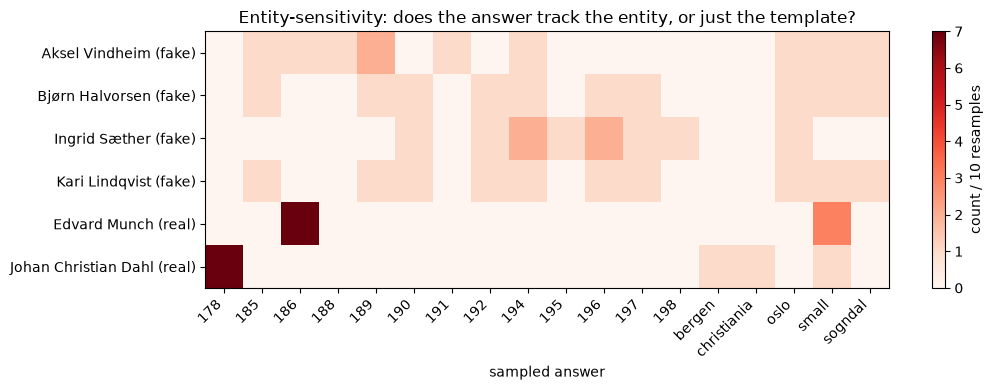

In [20]:
all_answers = sorted({a for c in entity_results.values() for a in c})
names = FAKE_NAMES + REAL_NAMES
matrix = np.array([[entity_results[n].get(a, 0) for a in all_answers] for n in names])

fig, ax = plt.subplots(figsize=(max(6, len(all_answers) * 0.6), 4))
im = ax.imshow(matrix, cmap="Reds", aspect="auto")
ax.set_xticks(range(len(all_answers)))
ax.set_xticklabels(all_answers, rotation=45, ha="right")
ax.set_yticks(range(len(names)))
ax.set_yticklabels([f"{n} ({'fake' if n in FAKE_NAMES else 'real'})" for n in names])
ax.set_xlabel("sampled answer")
plt.colorbar(im, ax=ax, label="count / 10 resamples")
ax.set_title("Entity-sensitivity: does the answer track the entity, or just the template?")
plt.tight_layout()
plt.savefig("figures/session1_entity_sensitivity.png", dpi=120)
plt.show()

**Splitting agreement by granularity.** Base-model fabrication is often sharp on
*format* and diffuse on *content*: for a year, the first token ("19") can have a huge
margin and near-100% agreement, while the full four-digit year scatters across
resamples. Comparing agreement at the first-token level vs. the full-answer level
separates "knows what kind of thing goes here" from "knows the thing."

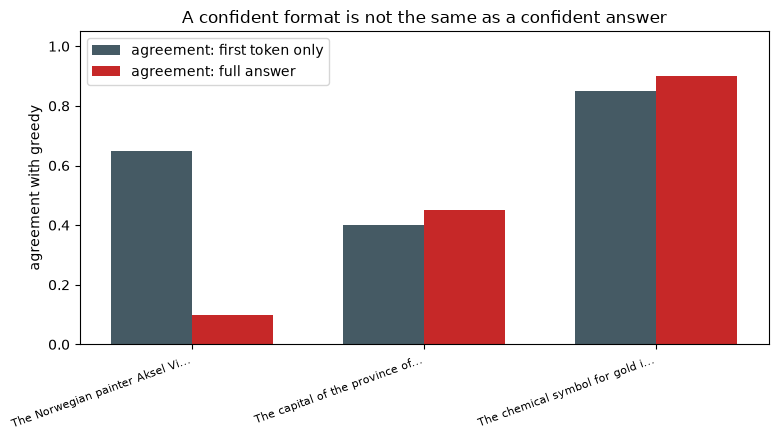

In [21]:
def granularity_split(model, tok, prompt, n=20, T=0.8):
    greedy = generate_with_topk_trace(model, tok, prompt=prompt, max_new_tokens=1, k=1, temperature=0.0)
    greedy_first_token = greedy.steps[0].picked_str
    greedy_full = canon(generate_with_topk_trace(
        model, tok, prompt=prompt, max_new_tokens=4, k=1, temperature=0.0,
    ).completed_text)

    first_tokens, full_answers = [], []
    for i in range(n):
        trace = generate_with_topk_trace(model, tok, prompt=prompt, max_new_tokens=4, k=1, temperature=T, seed=i)
        first_tokens.append(trace.steps[0].picked_str)
        full_answers.append(canon(trace.completed_text))

    first_token_agreement = sum(t == greedy_first_token for t in first_tokens) / n
    full_answer_agreement = sum(a == greedy_full for a in full_answers) / n
    return first_token_agreement, full_answer_agreement


granularity_prompts = [
    "The Norwegian painter Aksel Vindheim was born in",
    "The capital of the province of Terravesta is",
    "The chemical symbol for gold is",
]

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(granularity_prompts))
width = 0.35
first_vals, full_vals = [], []
for p in granularity_prompts:
    f, full = granularity_split(base_model, base_tokenizer, p)
    first_vals.append(f)
    full_vals.append(full)

ax.bar(x - width / 2, first_vals, width, label="agreement: first token only", color="#455a64")
ax.bar(x + width / 2, full_vals, width, label="agreement: full answer", color="#c62828")
ax.set_xticks(x)
ax.set_xticklabels([p[:30] + "..." for p in granularity_prompts], rotation=20, ha="right", fontsize=8)
ax.set_ylabel("agreement with greedy")
ax.set_ylim(0, 1.05)
ax.legend()
ax.set_title("A confident format is not the same as a confident answer")
plt.tight_layout()
plt.savefig("figures/session1_granularity.png", dpi=120)
plt.show()

A high first-token margin was never evidence of knowledge — only of a confident
format. That gap between the two bars is where "the model sounds sure" and "the model
knows" come apart, and it's exactly what retrieval and calibration training in later
sessions are aimed at closing.

**Does post-training fix hallucination, or hide it?** Run the same underlying
question through the instruct model, phrased the way a user actually would — a direct
chat question, not a sentence to complete — and compare against the base model's
result above. This isn't "same prompt, same model": it's the actual thing
post-training changed. If alignment training taught the model to recognize "I can't
know this," the instruct model's dot should move away from the base model's — either
toward lower margin (visibly less certain) or toward an explicit refusal in the
answer text itself, which is worth reading, not just plotting.

In [22]:
CONTRAST_PROMPTS = [
    ("My grandmother's maiden name was",
     "What was my grandmother's maiden name? Answer with one word."),
    ("The Norwegian painter Aksel Vindheim was born in",
     "In what year was the Norwegian painter Aksel Vindheim born? Answer with one word."),
]

contrast_results = []
for base_prompt, chat_prompt in CONTRAST_PROMPTS:
    base_r = score(base_model, base_tokenizer, base_prompt, n=20, T=0.8)
    instruct_r = score(model, tokenizer, chat_prompt, n=20, T=0.8, chat=True)
    contrast_results.append((base_prompt, base_r, instruct_r))
    print(f"base      {base_prompt!r}: margin={base_r['margin']:.2f}, answer={base_r['answer']!r}, agreement={base_r['agreement']:.0%}")
    print(f"instruct  {chat_prompt!r}: margin={instruct_r['margin']:.2f}, answer={instruct_r['answer']!r}, agreement={instruct_r['agreement']:.0%}")
    print()

base      "My grandmother's maiden name was": margin=0.57, answer='', agreement=0%
instruct  "What was my grandmother's maiden name? Answer with one word.": margin=1.50, answer='smith', agreement=60%

base      'The Norwegian painter Aksel Vindheim was born in': margin=2.11, answer='', agreement=0%
instruct  'In what year was the Norwegian painter Aksel Vindheim born? Answer with one word.': margin=9.00, answer='1', agreement=0%



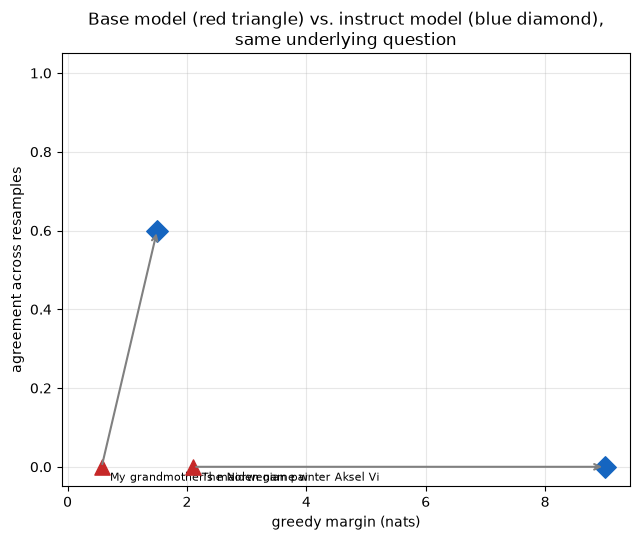

In [23]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for base_prompt, base_r, instruct_r in contrast_results:
    ax.scatter(base_r["margin"], base_r["agreement"], color="#c62828", marker="^", s=120, zorder=3)
    ax.scatter(instruct_r["margin"], instruct_r["agreement"], color="#1565c0", marker="D", s=120, zorder=3)
    ax.annotate("", xy=(instruct_r["margin"], instruct_r["agreement"]),
                xytext=(base_r["margin"], base_r["agreement"]),
                arrowprops=dict(arrowstyle="->", color="gray", lw=1.5))
    ax.annotate(base_prompt[:30], xy=(base_r["margin"], base_r["agreement"]),
                xytext=(6, -10), textcoords="offset points", fontsize=8)

ax.set_xlabel("greedy margin (nats)")
ax.set_ylabel("agreement across resamples")
ax.set_ylim(-0.05, 1.05)
ax.set_xlim(left=-0.1)
ax.grid(alpha=0.3)
ax.set_title("Base model (red triangle) vs. instruct model (blue diamond),\nsame underlying question")
plt.tight_layout()
plt.savefig("figures/session1_base_vs_instruct.png", dpi=120)
plt.show()

Read the arrows, then read the actual text in `instruct_r["answer"]` — that second
step matters. A dot moving down-left (lower margin, lower agreement) means
post-training made the model genuinely less certain. A dot that stays put but whose
answer is a refusal phrase rather than a fabricated name is a different, better
outcome: the model is now *consistently and confidently declining* — which looks
identical to confident hallucination on this plot alone, and is only visible by
reading what it actually said. Same honest limit as the quadrant plot, one level
deeper: even "did the position change" isn't enough — you have to read the content of
the consistent answer, not just its consistency.

---

## So what, for a working scientist

When you paste a paragraph into Claude or GPT and get a fluent reply, that reply was constructed by exactly this loop, one token at a time. Two consequences:

- **The model's own uncertainty at each token is invisible to you as an API user.** OpenAI's Chat API can return the top few `logprobs` on request; Anthropic's returns none; Google's returns limited scoring. If your literature-review workflow depends on knowing whether a specific claim in the model's output was *close* (the model almost said something else) or *committed* (all near-probability was on the one token), you cannot get that from a fully-closed API — but you can measure it on an open model that's plausibly *similar enough* to sanity-check your prompt design. Practical tip: when you catch an API model producing a fluent-but-wrong claim, running the same prompt through an open model of comparable size (or through OpenAI's `logprobs`-enabled endpoint) can reveal whether the top-1 was overwhelming or barely edging out an alternative. That distinction changes whether "try again" or "rewrite the prompt" is the right next move.

- **You don't need probabilities at all to catch inconsistency.** Part 8's resampling test works through a closed chat API exactly as it worked here: call the same prompt N times at temperature > 0 and check whether the answers agree. Low agreement is a real, API-visible signal that the model is guessing — no logprobs required. High agreement is *not* proof of truth (the quadrant plot's red top-right dots are confident and consistent and wrong), so this catches incoherent fabrication, not confident misbelief. Practical tip: for any claim you're about to rely on, don't trust a single response — resample it, and read the answers, not just count them.

- **The output is not a search over answers. It is a left-to-right commitment.** If the model made a wrong choice at token 3, everything from token 4 onwards was constructed to make token 3 look right in hindsight. Session 4 will show this happening explicitly ("snowballing"). Practical tip: this is why prompt engineering rewards *front-loading constraints*. Once the model has committed to an opening, its subsequent tokens are conditioned on that opening.

---

## Exercises

**1. Two models, same prompt.**
Load GPT-2 small (`"openai-community/gpt2"`) using `load_model_and_tokenizer`, and run `generate_with_topk_trace` on the same prompt as Qwen2.5-1.5B-Instruct. Compare top-5 lists at step 0. Which model is more confident on the top choice? Which produces more diverse alternatives? Why do you think that is? *(Hint: think about model size, training corpus, and post-training.)*

**2. Temperature sweep.**
For the prompt `"The best programming language is"`, run `generate_with_topk_trace` at temperatures 0.1, 0.5, 1.0, 1.5, with 20 samples each. Plot the entropy of the first token's picked-token distribution as a function of temperature. Does higher temperature reliably produce more diverse first tokens?

**3. Find a close call.**
Construct a prompt where the top-1 and top-2 candidates at token 1 have nearly equal probability (within a factor of 1.5). What does that prompt look like? Report both the prompt and the top-2 candidates. What does it mean, in terms of your trajectory picture, that these two candidates are so close?

**4. (Harder) Look-ahead probing.**
Modify `generate_with_topk_trace` — or write a small wrapper — that, in addition to recording what the model picked, records the log-probability of a *specific alternative continuation* the reader supplies. For a factual question the model gets wrong, supply the correct answer as the alternative continuation. Observe how the model's own probability for the correct answer evolves as it generates the wrong one.

*Exercise 4 is a preview of the sequence-mass ledger technique in Session 6 — it introduces the concept without naming it.*

## What you just did

- Loaded a language model and inspected its output distribution directly.
- Watched a generation happen at token resolution, with visible alternatives at every step.
- Built (a stripped-down version of) `generate_with_topk_trace`, the workshop's core diagnostic instrument.
- Visualized generation as a trajectory through possible paths, and saw the qualitative difference between confident and contested prompts.
- Encountered — but did not yet unpack — the ideas of trajectories, attractors, and semantic paths.
- Built a canonicalized confidence/consistency probe (margin + resampled agreement) on a base model, and used it to separate genuine knowledge from confident hallucination — while finding the method's own blind spot: a consistently wrong answer looks identical to a correct one.
- Probed the mechanism directly with an entity-swap test, distinguishing a fact (varies with the entity) from a slot prior (doesn't).
- Compared the base model to its instruction-tuned counterpart on the same underlying question, and watched post-training visibly change — or just disguise — the hallucination signature.

## Forward hook

The model has opinions at every step. To understand *where those opinions come from*, we need to look inside the box that produces them. **Session 2** gives you a confident tour of the transformer's architecture — enough to know what people mean when they say "attention head," "KV cache," or "residual stream," without doing any of the math.